In [139]:
import sys, os
sys.path.insert(0, os.path.abspath("../utils"))  # repo utils/ (vendored sweep + shared helpers)
import sys; sys.path.append("../utils")
from fft_sup_imports import * 
%matplotlib inline
update_rc_params('paper')
import copy

In [140]:
def zf_segment(analyzer, n_target, blims, dn=0.0):
    """Raw Rxx(B) at exactly n_target + dn over blims. No background subtraction."""
    B = np.asarray(analyzer.B_raw, float)
    Rxx = np.asarray(analyzer.Rxx_raw, float)
    order = np.argsort(B)
    B, Rxx = B[order], Rxx[order]
    keep = np.append(np.diff(B) > 0, True)     # drop repeated / flat-B points
    B, Rxx = B[keep], Rxx[keep]
    dens_order = np.argsort(analyzer.density)
    dens = np.asarray(analyzer.density, float)[dens_order]
    cut = np.array([np.interp(n_target + dn, dens, row[dens_order]) for row in Rxx])
    m = (blims[0] <= B) & (B <= blims[1]) & np.isfinite(cut)
    return B[m], cut[m]


['/Users/sandeshkalantre/repos/Fermiology-and-the-cCSC/figs/fig3_landau_fan_detrended.pdf',
 '/Users/sandeshkalantre/repos/Fermiology-and-the-cCSC/figs/fig3_landau_fan_detrended.png']

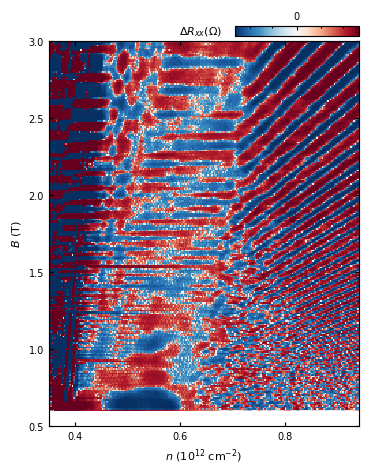

In [141]:
def plot_landau_fan_detrend(fig, ax, norm, cmap="viridis"):
    analyzer = Lf_analysis(1840, contact=1)
    n_vec = analyzer.density
    B_vec, Rxx_detrended = analyzer.get_bg_subtracted_data(bg_method=detrend_butterworth, \
                                              bg_method_params={'cutoff': None, 'order' : 4}, 
                                              blims=(0.2, 10), return_bg=False)
    
    plot = ax.pcolormesh(n_vec, B_vec, Rxx_detrended, norm=norm, cmap=cmap, rasterized=True)
    ax.set_xlabel(r'$n$ ($10^{12}$ cm$^{-2}$)')
    ax.set_ylabel(r'$B$ (T)')
    ax.set_xlim(0.35, 0.94)
    #ax.axvline(0.5, ls="--", color="white")
    #ax.axvline(0.62, ls="--", color="white")
    ax.set_ylim(0.5, 3)
    ax.xaxis.set_major_locator(plt.MaxNLocator(3))
    ax.yaxis.set_major_locator(plt.MaxNLocator(5))
    return plot


fig = plt.figure(figsize=(4,5))
ax = plt.gca()
norm = colors.SymLogNorm(linthresh=1, vmin=-0.05e3, vmax=0.05E3)
plot = plot_landau_fan_detrend(fig, ax, norm, "RdBu_r")

cax = fig.add_axes([0.59, 0.89, 0.31, 0.02])
cb = plt.colorbar(plot, cax=cax, ticks=SymmetricalLogLocator(base=10, linthresh=10), orientation='horizontal', shrink=0.3, anchor=(1., 0.9), pad=0.01, aspect=5)
cb = plt.colorbar(plot, cax=cax, ticks=[-1000, 0, 1000], \
                  orientation='horizontal')
cb.ax.annotate('$\Delta R_{xx} (\Omega)$', xy=(-0.10, 0.5), xycoords='axes fraction',
               ha='right', va='center', fontsize=plt.rcParams['axes.labelsize'])
cb.ax.xaxis.set_ticks_position('top')      # put ticks at the top
cb.ax.xaxis.set_label_position('top') 
cb.set_ticklabels(['$-10^3$', '$0$', '$10^3$'])
save_fig(fig, 'fig3_landau_fan_detrended')

30


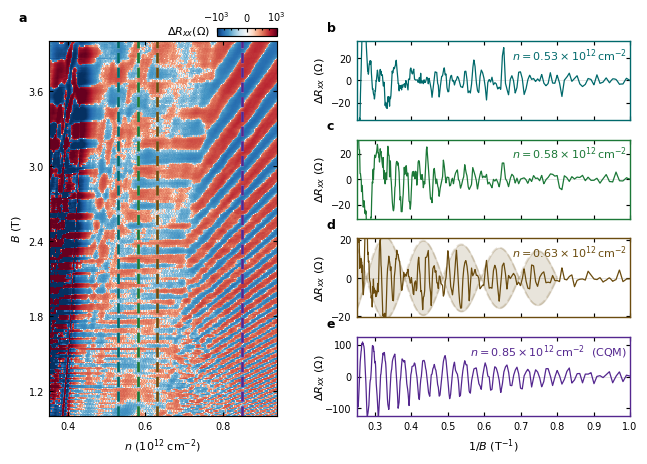

In [207]:
update_rc_params('paper')

# ── Global colorbar geometry ──────────────────────────────────────────────────
cb_width = 0.08          # colorbar width in figure fraction
cb_height_inches = 0.08  # colorbar height in physical inches (fixed across fig sizes)
# ─────────────────────────────────────────────────────────────────────────────

wf_targets = [0.53, 0.58, 0.63, 0.85]
wf_cqm_idx = 3
wf_invB    = (0.25, 1.0)                     # display and detrending window, in 1/B
wf_zoom    = (1/wf_invB[1], 1/wf_invB[0])
wf_colors = ['#00696B', '#1B7837', '#6B4C0F', '#54278F']   # teal, green, dark amber, purple
WF_BG      = {'cutoff': None, 'order': 4}
WF_NINV    = 2048

analyzer_lowB = Lf_analysis(1840, contact=1)

nrows = len(wf_targets)
fig = plt.figure(figsize=(7.5, 5))
gs = GridSpec(nrows, 2, figure=fig, width_ratios=[1, 1.2],
              wspace=0.32, hspace=0.25, top=0.86)
ax_fan = fig.add_subplot(gs[:, 0])
axes_cut = [fig.add_subplot(gs[i, 1]) for i in range(nrows)]

cb_height_frac = cb_height_inches / fig.get_size_inches()[1]
label_spacer = 0.04

################ Panel a: detrended Landau fan ##################
norm = colors.SymLogNorm(linthresh=1, vmin=-1e3, vmax=1e3)
plot = plot_landau_fan_detrend(fig, ax_fan, norm, "RdBu_r")
ax_fan.set_ylim(*wf_zoom)

for n, c in zip(wf_targets, wf_colors):
    ax_fan.axvline(n, color=c, ls='--', lw=2,
                   path_effects=[pe.Stroke(linewidth=1.8, foreground='w'),
                                 pe.Normal()])

fig.canvas.draw()
pos = ax_fan.get_position()
fig.text(pos.x0 - label_spacer, pos.y1 + label_spacer, "a", fontweight='bold')

cax = fig.add_axes([pos.x1 - cb_width, pos.y1 + 0.01, cb_width, cb_height_frac])
cb = plt.colorbar(plot, cax=cax, ticks=[-1000, 0, 1000], orientation='horizontal')
cb.ax.annotate(r'$\Delta R_{xx} (\Omega)$', xy=(-0.10, 0.5), xycoords='axes fraction',
               ha='right', va='center', fontsize=plt.rcParams['axes.labelsize'])
cb.ax.xaxis.set_ticks_position('top')
cb.ax.xaxis.set_label_position('top')
cb.set_ticklabels(['$-10^3$', '$0$', '$10^3$'])

################ Panels b-e: linecuts ##################
letters = ['b', 'c', 'd', 'e']
xi = np.linspace(*wf_invB, WF_NINV)          # uniform grid in 1/B (T^-1), used for both
                                             # detrending and plotting

for i, (n, color, ax) in enumerate(zip(wf_targets, wf_colors, axes_cut)):
    B, Rxx = zf_segment(analyzer_lowB, n, wf_zoom)
    inv = 1.0/np.asarray(B, float)           # 1/B of the raw trace, T^-1
    o   = np.argsort(inv)                    # np.interp needs increasing x
    Ri  = np.interp(xi, inv[o], np.asarray(Rxx, float)[o])   # Rxx on the uniform 1/B grid
    y, bg = detrend_butterworth(xi, Ri, **WF_BG)             # filter in 1/B, as intended

    ax.axhline(0, color='0.85', lw=0.5, zorder=0)
    ax.plot(xi, y, lw=0.9, color=color)

    envelope_amps = [40,40,30]
    envelope_fs = [32, 30, 30]
    if i in [2]:
        # add envelope
        f_env = envelope_fs[i] # envelope frequency in inverse T
        print(envelope_amps[i])
        Renv = envelope_amps[i]*np.sin(xi*f_env - 2)*np.exp(-xi)
        env_pts = 1500
        ax.plot(xi[:env_pts], Renv[:env_pts], color=color, alpha=0.15, ls="--")
        ax.plot(xi[:env_pts], -Renv[:env_pts], color=color, alpha=0.15, ls="--")
        ax.fill_between(xi[:env_pts], Renv[:env_pts], -Renv[:env_pts], color=color, alpha=0.15)
    
    ax.set_xlim(*wf_invB)
    ax.set_ylabel(r'$\Delta R_{xx}$ ($\Omega$)')
    ax.locator_params(axis='y', nbins=4, steps=[1, 2, 5, 10])
    ax.yaxis.set_label_coords(-0.11, 0.5)
    ylim = 1.2*np.max(np.abs(y[220:]))
    ax.set_ylim(-ylim, ylim)

    for spine in ax.spines.values():
        spine.set_edgecolor(color)
        spine.set_linewidth(1.0)

    lbl = rf'$n = {n:.2f} \times 10^{{12}}\,\mathrm{{cm}}^{{-2}}$'
    lbl += '  (CQM)' if i == wf_cqm_idx else ''
    ax.annotate(lbl, (0.99, 0.93), xycoords='axes fraction', ha='right',
                va='top', color=color, fontsize=8)

    if i == nrows - 1:
        ax.set_xlabel(r'$1/B$ (T$^{-1}$)')
    else:
        ax.tick_params(labelbottom=False)

fig.canvas.draw()
for letter, ax in zip(letters, axes_cut):
    pos = ax.get_position()
    fig.text(pos.x0 - label_spacer, pos.y1 + 0.5*label_spacer, letter,
             fontweight='bold')

plt.rcParams['svg.fonttype'] = 'none'
fig.savefig("figS_fan_and_linecuts.pdf", dpi=600, bbox_inches='tight',
            pad_inches=0.02, transparent=False)
